# **PDBe-KB hotspots -> ligands -> fast parallel docking (P22303) - Google Colab version**

**How PDBe notebook connects to docking.** The `ligand_sites` table from the PDBe-KB Graph API has one row per *ligand x residue x PDB entry*:
1. **Residue statistics:** the per-residue *count* in scatter plot = number of (ligand, PDB entry) contacts on that residue.
2. **Hotspots:** residues above the threshold (notebook: `2 x SD`, about 29 for P22303 - the line in your figure).
3. **Ligands:** every ligand that touches at least one hotspot residue (your `unique_substantially_int_ligs` list). These are the ligands we dock.
4. **Grid box:** the hotspot residues, plus the **UniProt** active/binding-site residues, define the box (BioBB `box_residues`), capped to a maximum size so Vina stays fast.
5. **Check:** after docking, each pose is tested for how many hotspot residues it actually contacts.

## 0. Installation (one cell, no restart)
Colab has internet by default.

In [ ]:
import sys, os, shutil, subprocess, urllib.request, socket

IN_COLAB = 'google.colab' in sys.modules
CAN_APT = bool(shutil.which("apt-get")) and hasattr(os, "geteuid") and os.geteuid() == 0

try:
    socket.gethostbyname("pypi.org")
except OSError:
    raise RuntimeError("No internet. Kaggle: right panel -> Session options -> Internet -> ON, then re-run. ")

subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "biobb_io", "biobb_structure_utils", "biobb_chemistry", "biobb_vs",
                "biobb_structure_checking", "biopython", "nglview",
                "pandas", "matplotlib", "requests"], check=True)

if not shutil.which("obabel") and CAN_APT:
    subprocess.run("apt-get -qq update && apt-get -qq install -y openbabel", shell=True, check=True)

if not shutil.which("vina"):
    try:
        urllib.request.urlretrieve("https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/v1.2.5/vina_1.2.5_linux_x86_64",
                                   "/usr/local/bin/vina")
        os.chmod("/usr/local/bin/vina", 0o755)
    except Exception as e:
        print("Vina download failed:", e, "-> trying apt")
        if CAN_APT:
            subprocess.run("apt-get -qq install -y autodock-vina", shell=True, check=True)

if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

print("\nTool check:")
for tool in ["obabel", "vina", "check_structure"]:
    print(f"  {tool:<16} {shutil.which(tool) or 'NOT FOUND'}")
print("  CPU cores:", os.cpu_count())

# ---- Environment record (copy these lines into the Methods section) ----
import platform, importlib.metadata as md
print("\nEnvironment record:")
print("  Platform       :", "Kaggle" if os.path.isdir("/kaggle") else ("Google Colab" if IN_COLAB else platform.platform()))
print("  Python         :", sys.version.split()[0])
print("  CPU cores      :", os.cpu_count(), "| GPU present (not used by Vina):", shutil.which("nvidia-smi") is not None)
for pkg in ["biobb_io", "biobb_structure_utils", "biobb_chemistry", "biobb_vs", "biobb_structure_checking", "biopython", "pandas", "numpy"]:
    try: print(f"  {pkg:<26}", md.version(pkg))
    except Exception: print(f"  {pkg:<26} not found")
for cmd in (["vina", "--version"], ["obabel", "-V"]):
    try:
        o = subprocess.run(cmd, capture_output=True, text=True)
        print("  " + (o.stdout or o.stderr).strip().splitlines()[0])
    except Exception as e:
        print("  ", cmd[0], "version not available:", e)


Tool check:
  obabel           /usr/bin/obabel
  vina             /usr/local/bin/vina
  check_structure  /usr/local/bin/check_structure
  CPU cores: 2

Environment record:
  Platform       : Kaggle
  Python         : 3.13.16
  CPU cores      : 2 | GPU present (not used by Vina): False
  biobb_io                   5.3.1
  biobb_structure_utils      5.3.0
  biobb_chemistry            5.3.0
  biobb_vs                   5.3.0
  biobb_structure_checking   3.16.3
  biopython                  1.88
  pandas                     2.2.3
  numpy                      2.1.3
  AutoDock Vina v1.2.5
  Open Babel 3.1.1 -- Mar 31 2024 -- 06:39:03


## 1. Parameters

In [ ]:
import os, re, time, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, as_completed
from Bio.PDB import PDBParser

T_START = time.perf_counter()
root = "docking_P22303"
os.makedirs(root, exist_ok=True)

uniprot_id = "P22303"        #@param {type:"string"}

# ---- Speed / quality profile ----
PROFILE = "standard"         #@param ["fast", "standard", "thorough"]
PROFILES = {"fast":     dict(exhaustiveness=4,  num_modes=5, max_box_side=26),
             "standard": dict(exhaustiveness=8,  num_modes=9, max_box_side=30),
             "thorough": dict(exhaustiveness=16, num_modes=9, max_box_side=34)}
exhaustiveness = PROFILES[PROFILE]["exhaustiveness"]
num_modes      = PROFILES[PROFILE]["num_modes"]
max_box_side   = PROFILES[PROFILE]["max_box_side"]     # A, the grid box is shrunk until it fits

# ---- Hotspot rule ----
threshold_rule = "2xSD"      #@param ["2xSD", "mean+2SD", "fixed"]
#   "2xSD"     = your PDBe notebook (count > 2 x SD; ~29 for P22303, the line in your figure)
#   "mean+2SD" = wording of the abstract (count > mean + 2 x SD)
fixed_threshold = 30         #@param {type:"number"}   used only if threshold_rule = "fixed"
exclude_additives_from_counts = False   # False reproduces your figure (ions/additives are counted)

# ---- Ligands ----
ligand_scope = "hotspot"     #@param ["hotspot", "all"]   hotspot = ligands touching hotspot residues; all = every PDBe-KB ligand
skip_additives = False       #@param {type:"boolean"}   False = dock everything like the manual workflow (ligands that cannot be converted to PDBQT, e.g. CL and NA, are skipped automatically)
min_atoms    = 1             #@param {type:"integer"}   0/None = no lower limit
max_atoms    = None          # None = no upper limit
max_torsions = 32            #@param {type:"integer"}    Vina supports up to 32 torsions; lower it (e.g. 20) to skip very flexible, slow ligands
max_ligands  = None          # None = all; set e.g. 5 for a quick test run

# ---- Box ----
use_uniprot_sites = True     #@param {type:"boolean"}   add UniProt Active/Binding site residues to the box
box_offset        = 4        #@param {type:"number"}    A added around the selected residues

# ---- Run control ----
n_workers   = os.cpu_count() or 2      # ligands docked at the same time (1 core each)
max_minutes = None           # None = no limit. e.g. 90 = ligands not started within 90 min are skipped
use_biobb_vina = True        # BioBB autodock_vina_run (cannot be time-limited); ignored when ligand_timeout_min is set
ligand_timeout_min = None    # None = no limit, BioBB engine (default). e.g. 8 = kill a ligand running > 8 min (then the vina binary is used directly)
order_by = "easiest_first"   #@param ["easiest_first", "as_listed"]   dock low-torsion ligands first so most finish early
reduce_exh_for_flexible = False   #@param {type:"boolean"}   halve exhaustiveness for very flexible ligands (faster, less reliable)
flex_torsions = 15           #@param {type:"integer"}
resume = True                # reuse finished results in the output folder (set False to redo everything, e.g. after changing the profile)
n_parts = 1                  # split the ligand list over several machines/sessions: run this notebook once per part (part = 1 ... n_parts)
part    = 1
pose_contact_cutoff = 4.0    # A, for the hotspot-contact check of each pose

EXCLUDE = {"HOH","GOL","EDO","PEG","PGE","PG4","PE8","7PE","1PE","SO4","PO4","NAG","BMA","MAN","FUC","NA","CL","K","MG","ZN","CA","ACT","FMT","DMS","TRS","MES","EPE","BOG","CIT","NO3"}
print(f"Profile={PROFILE}  exhaustiveness={exhaustiveness}  max box side={max_box_side} A  workers={n_workers}")

Profile=standard  exhaustiveness=8  max box side=30 A  workers=2


## 2. Helpers

In [ ]:
PDBEKB = "https://www.ebi.ac.uk/pdbe/graph-api/uniprot/"

def get_url(url):
    r = requests.get(url, timeout=60)
    if r.status_code == 200:
        return r.json()
    print(f"[No data - {r.status_code}] {url}")
    return {}

def get_ligand_profile(uid):
    """PDBe-KB ligand_sites -> one row per (ligand, residue)."""
    rows = []
    for acc, acc_data in get_url(PDBEKB + "ligand_sites/" + uid).items():
        for row in acc_data.get("data", []):
            info = row.get("additionalData") or {}
            for res in row.get("residues", []):
                rows.append({"accession": row.get("accession"), "name": row.get("name"),
                             "num_atoms": info.get("numAtoms"), "residue_number": res.get("startIndex"),
                             "n_interactions": len(res.get("interactingPDBEntries", []))})
    return pd.DataFrame(rows)

def residue_counts(lig_df, drop_additives=False):
    d = lig_df[lig_df["n_interactions"] > 0]
    if drop_additives:
        d = d[~d["accession"].isin(EXCLUDE)]
    return d.groupby("residue_number")["n_interactions"].sum().rename("count").reset_index()

def call_hotspots(counts, rule, fixed):
    mean, sd = counts["count"].mean(), counts["count"].std(ddof=1)
    thr = {"2xSD": 2 * sd, "mean+2SD": mean + 2 * sd, "fixed": fixed}[rule]
    return mean, sd, thr, counts[counts["count"] > thr]["residue_number"].astype(int).tolist()

def afdb_model(uid, outdir):
    r = requests.get(f"https://alphafold.ebi.ac.uk/api/prediction/{uid}", timeout=30); r.raise_for_status()
    path = os.path.join(outdir, f"{uid}_alphafold.pdb")
    with open(path, "wb") as fh:
        fh.write(requests.get(r.json()[0]["pdbUrl"], timeout=60).content)
    chain = PDBParser(QUIET=True).get_structure(uid, path)[0]["A"]
    return path, chain, {res.id[1]: res["CA"].get_bfactor() for res in chain if "CA" in res}

def uniprot_sites(uid):
    """Active-site / binding-site residues annotated in UniProt."""
    sites = {}
    for f in get_url(f"https://rest.uniprot.org/uniprotkb/{uid}.json").get("features", []):
        if f.get("type") in ("Active site", "Binding site"):
            s, e = f["location"]["start"]["value"], f["location"]["end"]["value"]
            if s is not None and e is not None and e - s <= 4:
                for r in range(s, e + 1):
                    sites[r] = f["type"]
    return sites

def select_box_residues(chain, weights, protected, offset, max_side):
    """Keep the residues whose box (all atoms +/- offset) fits in max_side; drop the farthest from the weighted centre first."""
    atoms = {r.id[1]: np.array([a.coord for a in r]) for r in chain if r.id[1] in weights and "CA" in r}
    ca = {r.id[1]: r["CA"].coord for r in chain if r.id[1] in atoms}
    keep = set(atoms)
    def side(k):
        xyz = np.vstack([atoms[r] for r in k]); return xyz.max(0) - xyz.min(0) + 2 * offset
    while side(keep).max() > max_side:
        removable = [r for r in keep if r not in protected]
        if len(removable) == 0 or len(keep) <= 3:
            print("WARNING: protected (UniProt) residues alone exceed the maximum box size")
            break
        w = np.array([weights[r] for r in keep], float)
        centre = (np.array([ca[r] for r in keep]) * w[:, None]).sum(0) / w.sum()
        keep.remove(max(removable, key=lambda r: np.linalg.norm(ca[r] - centre)))
    return sorted(keep), side(keep)

## 3. AlphaFold model

In [ ]:
t = time.perf_counter(); TIMINGS = {}
af_pdb, chain, plddt = afdb_model(uniprot_id, root)
v = np.array(list(plddt.values()))
print(f"{uniprot_id}: {len(v)} residues | mean pLDDT {v.mean():.2f} | {(v > 90).mean()*100:.1f}% > 90")
rec_xyz, rec_res = [], []
for r in chain:
    for a in r:
        rec_xyz.append(a.coord); rec_res.append(r.id[1])
rec_xyz, rec_res = np.array(rec_xyz), np.array(rec_res)
TIMINGS["alphafold"] = time.perf_counter() - t

P22303: 614 residues | mean pLDDT 92.94 | 85.2% > 90


## 4. PDBe-KB: residue statistics -> hotspots (reproduces your figure)

64 ligands in PDBe-KB | mean 8.9 | SD 14.6 | rule 2xSD -> threshold 29.3
24 hotspot residues: [103, 117, 152, 153, 155, 233, 234, 235, 267, 272, 296, 317, 326, 328, 368, 369, 372, 375, 376, 378, 380, 381, 478, 565]


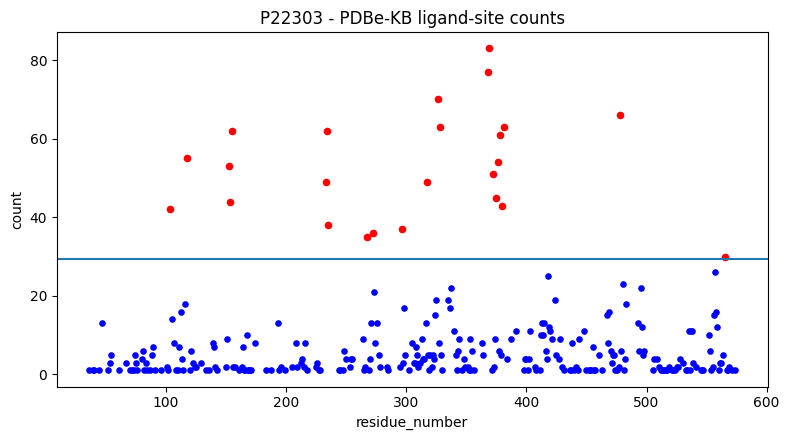

In [ ]:
t = time.perf_counter()
lig_df = get_ligand_profile(uniprot_id)
assert not lig_df.empty, "No PDBe-KB ligand_sites data for this UniProt ID"
counts = residue_counts(lig_df, exclude_additives_from_counts)
mean, sd, thr, hotspots = call_hotspots(counts, threshold_rule, fixed_threshold)
hotspot_set = set(hotspots)
print(f"{lig_df['accession'].nunique()} ligands in PDBe-KB | mean {mean:.1f} | SD {sd:.1f} | rule {threshold_rule} -> threshold {thr:.1f}")
print(f"{len(hotspots)} hotspot residues:", sorted(hotspots))

fig, ax = plt.subplots(figsize=(8, 4.5)); hot = counts["residue_number"].isin(hotspot_set)
ax.scatter(counts.loc[~hot, "residue_number"], counts.loc[~hot, "count"], c="blue", s=14)
ax.scatter(counts.loc[hot, "residue_number"], counts.loc[hot, "count"], c="red", s=20)
ax.axhline(thr); ax.set_xlabel("residue_number"); ax.set_ylabel("count"); ax.set_title(f"{uniprot_id} - PDBe-KB ligand-site counts")
plt.tight_layout(); plt.savefig(os.path.join(root, "hotspot_profile.png"), dpi=300); plt.show()
TIMINGS["pdbe_kb"] = time.perf_counter() - t

## 5. Ligands that interact with the hotspot residues (additives are flagged, not removed)

In [ ]:
pos = lig_df[lig_df["n_interactions"] > 0]
per_lig = lig_df.groupby("accession").agg(name=("name", "first"), num_atoms=("num_atoms", "first")).reset_index()   # every PDBe-KB ligand
touch = pos[pos["residue_number"].isin(hotspot_set)].groupby("accession")["residue_number"].nunique()
per_lig["hotspot_residues"] = per_lig["accession"].map(touch).fillna(0).astype(int)
if ligand_scope == "hotspot":
    per_lig = per_lig[per_lig["hotspot_residues"] > 0]

why = []
per_lig["additive"] = per_lig["accession"].isin(EXCLUDE)    # ion / buffer / sugar / crystallisation additive (flag only)
for _, r in per_lig.iterrows():
    na = r["num_atoms"]
    if skip_additives and r["additive"]:                       why.append("ion / additive / sugar")
    elif pd.notna(na) and min_atoms and na < min_atoms:        why.append(f"< {min_atoms} atoms")
    elif pd.notna(na) and max_atoms and na > max_atoms:        why.append(f"> {max_atoms} atoms")
    else:                                                      why.append("")
per_lig["skip_reason"] = why
skipped = per_lig[per_lig["skip_reason"] != ""]
ligands = (per_lig[per_lig["skip_reason"] == ""].sort_values(["hotspot_residues", "num_atoms"], ascending=[False, True]).reset_index(drop=True))
if max_ligands: ligands = ligands.head(max_ligands)
print(f"Ligands in PDBe-KB: {lig_df['accession'].nunique()} | in scope ({ligand_scope}): {len(per_lig)} | skipped: {len(skipped)} | to dock: {len(ligands)}")
print("Skipped:", dict(zip(skipped['accession'], skipped['skip_reason'])))
display(ligands)

Ligands in PDBe-KB: 64 | in scope (hotspot): 58 | skipped: 0 | to dock: 58
Skipped: {}


,accession,name,num_atoms,hotspot_residues,additive,skip_reason
0,GOL,GLYCEROL,6.0,14,True,
1,4J1,"(2R,3R,4S,5S,6R)-2-[4-[1-[4-[6-[(Z)-hydroxyimi...",35.0,14,False,
2,VX,O-ETHYLMETHYLPHOSPHONIC ACID ESTER GROUP,7.0,13,False,
3,CVZ,3-[(~{E})-5-[ethyl-[(2-nitrophenyl)methyl]amin...,45.0,13,False,
4,CL,CHLORIDE ION,1.0,12,True,
5,L2Y,(S)-N-[(1E)-1-(diethylamino)ethylidene]-P-meth...,12.0,12,False,
6,L0S,methyl (R)-N-[(1E)-1-(diethylamino)ethylidene]...,13.0,12,False,
7,L1M,ethyl (R)-N-[(1E)-1-(diethylamino)ethylidene]p...,13.0,12,False,
8,LWU,1-(2-(2-((6-(dihydroxymethyl)-2-phenylpyrimidi...,27.0,12,False,
9,EBW,4-(5-{4-[DIMETHYL(PROP-2-ENYL)AMMONIO]PHENYL}-...,30.0,12,False,


## 6. Receptor and grid box
Seeds = hotspot residues + UniProt Active/Binding-site residues. UniProt gives *residue positions*, not box dimensions, so the box is computed from their coordinates on the AlphaFold model (BioBB `box_residues`) and shrunk to `max_box_side`.

In [ ]:
t = time.perf_counter()
from biobb_structure_utils.utils.str_check_add_hydrogens import str_check_add_hydrogens
from biobb_vs.utils.box_residues import box_residues

cmax = int(counts["count"].max())
weights = {int(r): int(c) for r, c in zip(counts["residue_number"], counts["count"]) if int(r) in hotspot_set}
protected = set()
if use_uniprot_sites:
    sites = uniprot_sites(uniprot_id)
    print("UniProt active/binding-site residues:", sites)
    for r in sites:
        weights.setdefault(r, cmax); protected.add(r)
        print(f"  residue {r} ({sites[r]}) is {'a PDBe-KB hotspot' if r in hotspot_set else 'not a hotspot'}")

box_res, box_side = select_box_residues(chain, weights, protected, box_offset, max_box_side)
print(f"Box residues ({len(box_res)}): {box_res}")

receptor = os.path.join(root, "prep_receptor.pdbqt")
str_check_add_hydrogens(input_structure_path=af_pdb, output_structure_path=receptor,
                        properties={"charges": True, "mode": "auto"})

box_pdb = os.path.join(root, "box.pdb")
box_residues(input_pdb_path=af_pdb, output_pdb_path=box_pdb,
             properties={"resid_list": box_res, "offset": box_offset, "box_coordinates": True})

# All-atom envelope of the selected residues (+ offset): used only to prune the residue list above
xyz = np.vstack([np.array([a.coord for a in r]) for r in chain if r.id[1] in set(box_res)])
lo, hi = xyz.min(0) - box_offset, xyz.max(0) + box_offset
env_center, env_size = (lo + hi) / 2, hi - lo

# The box that BioBB actually writes (and Vina actually uses) - read it back from box.pdb
def read_biobb_box(path):
    for line in open(path):
        if "CENTER" in line.upper() and "SIZE" in line.upper():
            nums = [float(x) for x in re.findall(r"-?\d+\.\d+", line)]
            if len(nums) >= 6:
                return np.array(nums[-6:-3]), np.array(nums[-3:])
    return None, None

BOX_CENTER, BOX_SIZE = read_biobb_box(box_pdb)
if BOX_CENTER is None:
    print("WARNING: could not read the BioBB box from box.pdb - showing the all-atom envelope instead. box.pdb header lines:")
    print("".join(l for l in open(box_pdb) if l.startswith("REMARK"))[:600])
    BOX_CENTER, BOX_SIZE = env_center, env_size
print("Box used by Vina (BioBB box_residues):")
print("  center (A): x={:.2f} y={:.2f} z={:.2f}".format(*BOX_CENTER))
print("  size   (A): x={:.2f} y={:.2f} z={:.2f}".format(*BOX_SIZE))
print("All-atom envelope of the selected residues (used only to choose them): size x={:.1f} y={:.1f} z={:.1f}".format(*env_size))
TIMINGS["receptor_and_box"] = time.perf_counter() - t

UniProt active/binding-site residues: {234: 'Binding site', 365: 'Active site', 478: 'Binding site', 117: 'Binding site', 153: 'Binding site', 164: 'Binding site', 233: 'Binding site', 368: 'Binding site', 470: 'Binding site'}
  residue 234 (Binding site) is a PDBe-KB hotspot
  residue 365 (Active site) is not a hotspot
  residue 478 (Binding site) is a PDBe-KB hotspot
  residue 117 (Binding site) is a PDBe-KB hotspot
  residue 153 (Binding site) is a PDBe-KB hotspot
  residue 164 (Binding site) is not a hotspot
  residue 233 (Binding site) is a PDBe-KB hotspot
  residue 368 (Binding site) is a PDBe-KB hotspot
  residue 470 (Binding site) is not a hotspot
Box residues (15): [117, 152, 153, 155, 164, 233, 234, 235, 326, 365, 368, 369, 372, 470, 478]
2026-10-18 15:43:15,407 [MainThread  ] [INFO ]  Module: biobb_structure_utils.utils.str_check_add_hydrogens Version: 5.3.0


INFO:log.out:Module: biobb_structure_utils.utils.str_check_add_hydrogens Version: 5.3.0


2026-10-18 15:43:15,409 [MainThread  ] [INFO ]  Directory successfully created: /content/sandbox_f418f72f-082d-4f87-a814-169d74538fa5


INFO:log.out:Directory successfully created: /content/sandbox_f418f72f-082d-4f87-a814-169d74538fa5


2026-10-18 15:43:15,413 [MainThread  ] [INFO ]  Copy to stage: /content/docking_P22303/P22303_alphafold.pdb --> sandbox_f418f72f-082d-4f87-a814-169d74538fa5


INFO:log.out:Copy to stage: /content/docking_P22303/P22303_alphafold.pdb --> sandbox_f418f72f-082d-4f87-a814-169d74538fa5


... (33 outputs left out)

INFO:log_1.out:Saving output PDB file (with box setting annotations): docking_P22303/box.pdb


2026-10-18 15:43:18,742 [MainThread  ] [INFO ]  Removed: ['/content/sandbox_bf37fdc6-03c5-4881-bfc6-337373ecd1f8']


INFO:log_1.out:Removed: ['/content/sandbox_bf37fdc6-03c5-4881-bfc6-337373ecd1f8']


Box used by Vina (BioBB box_residues):
  center (A): x=3.47 y=1.44 z=-1.02
  size   (A): x=14.16 y=13.79 z=14.63
All-atom envelope of the selected residues (used only to choose them): size x=29.4 y=26.5 z=27.8


## 7. Prepare all ligands in parallel (PDBe ideal SDF -> PDBQT)

In [ ]:
t = time.perf_counter()
from biobb_io.api.ideal_sdf import ideal_sdf
from biobb_chemistry.babelm.babel_convert import babel_convert

lig_dir = os.path.join(root, "ligands"); os.makedirs(lig_dir, exist_ok=True)

def prepare_ligand(code):
    sdf, pdbqt = os.path.join(lig_dir, f"{code}.sdf"), os.path.join(lig_dir, f"{code}.pdbqt")
    if resume and os.path.exists(pdbqt) and os.path.getsize(pdbqt) > 0:      # already prepared
        m = re.search(r"TORSDOF\s+(\d+)", open(pdbqt).read())
        return pdbqt, int(m.group(1)) if m else -1
    try:
        ideal_sdf(output_sdf_path=sdf, properties={"ligand_code": code})
    except Exception:
        pass
    if not (os.path.exists(sdf) and os.path.getsize(sdf) > 0):      # direct download fallback
        r = requests.get(f"https://www.ebi.ac.uk/pdbe/static/files/pdbechem_v2/{code}_ideal.sdf", timeout=60)
        r.raise_for_status(); open(sdf, "wb").write(r.content)
    babel_convert(input_path=sdf, output_path=pdbqt,
                  properties={"input_format": "sdf", "output_format": "pdbqt", "binary_path": "obabel"})
    if not (os.path.exists(pdbqt) and os.path.getsize(pdbqt) > 0):
        raise RuntimeError("PDBQT conversion failed")
    m = re.search(r"TORSDOF\s+(\d+)", open(pdbqt).read())
    return pdbqt, int(m.group(1)) if m else -1

ligand_files, torsions, prep_failed = {}, {}, {}
with ThreadPoolExecutor(max_workers=8) as ex:
    futs = {ex.submit(prepare_ligand, c): c for c in ligands["accession"]}
    for f in as_completed(futs):
        c = futs[f]
        try:
            ligand_files[c], torsions[c] = f.result()
        except Exception as e:
            prep_failed[c] = str(e)[:80]
too_flexible = [c for c, n in torsions.items() if n > max_torsions]
for c in too_flexible: ligand_files.pop(c)
print(f"Prepared: {len(ligand_files)} | could not be converted to PDBQT (skipped): {prep_failed} | skipped (> {max_torsions} torsions): {too_flexible}")
TIMINGS["ligand_prep"] = time.perf_counter() - t
print(f"Ligand preparation took {TIMINGS['ligand_prep']:.1f} s")

2026-10-18 15:43:19,024 [ThreadPoolEx] [INFO ]  Module: biobb_io.api.ideal_sdf Version: 5.3.1
2026-10-18 15:43:19,035 [ThreadPoolEx] [INFO ]  Module: biobb_io.api.ideal_sdf Version: 5.3.1
2026-10-18 15:43:19,047 [ThreadPoolEx] [INFO ]  Module: biobb_io.api.ideal_sdf Version: 5.3.1
2026-10-18 15:43:19,058 [ThreadPoolEx] [INFO ]  Module: biobb_io.api.ideal_sdf Version: 5.3.1


INFO:log_2.out:Module: biobb_io.api.ideal_sdf Version: 5.3.1
INFO:log_3.out:Module: biobb_io.api.ideal_sdf Version: 5.3.1


2026-10-18 15:43:19,063 [ThreadPoolEx] [INFO ]  Module: biobb_io.api.ideal_sdf Version: 5.3.1
2026-10-18 15:43:19,085 [ThreadPoolEx] [INFO ]  Module: biobb_io.api.ideal_sdf Version: 5.3.1
2026-10-18 15:43:19,077 [ThreadPoolEx] [INFO ]  Module: biobb_io.api.ideal_sdf Version: 5.3.1


INFO:log_5.out:Module: biobb_io.api.ideal_sdf Version: 5.3.1


2026-10-18 15:43:19,100 [ThreadPoolEx] [INFO ]  Module: biobb_io.api.ideal_sdf Version: 5.3.1


INFO:log_4.out:Module: biobb_io.api.ideal_sdf Version: 5.3.1
INFO:log_6.out:Module: biobb_io.api.ideal_sdf Version: 5.3.1
INFO:log_7.out:Module: biobb_io.api.ideal_sdf Version: 5.3.1
INFO:log_8.out:Module: biobb_io.api.ideal_sdf Version: 5.3.1
INFO:log_9.out:Module: biobb_io.api.ideal_sdf Version: 5.3.1


... (989 outputs left out)

INFO:log_112.out:Removed: ['/content/sandbox_afb1a72e-9122-4f77-ad58-a96a6bc9f75f']


2026-10-18 15:43:29,666 [ThreadPoolEx] [INFO ]  


INFO:log_112.out:


Prepared: 58 | could not be converted to PDBQT (skipped): {} | skipped (> 32 torsions): []
Ligand preparation took 10.8 s


## 8. Dock all ligands in parallel
One core per ligand, `n_workers` ligands at a time. The docking time of **every ligand** and a running ETA are printed as results arrive. Ligands not started within `max_minutes` are skipped (their rows are marked).

In [ ]:
from biobb_vs.vina.autodock_vina_run import autodock_vina_run

VINA_RE = re.compile(r"REMARK VINA RESULT:\s+(-?\d+\.\d+)")
def best_affinity(pdbqt):
    if not (os.path.exists(pdbqt) and os.path.getsize(pdbqt) > 0): return np.nan
    hits = [float(x) for x in VINA_RE.findall(open(pdbqt).read())]
    return min(hits) if hits else np.nan

def pose_hotspot_contacts(pdbqt):
    xyz = []
    for line in open(pdbqt):
        if line.startswith("ENDMDL"): break
        if line.startswith(("ATOM", "HETATM")):
            xyz.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
    if not xyz: return 0, 0
    lig = np.array(xyz)
    d = np.linalg.norm(rec_xyz[:, None, :] - lig[None, :, :], axis=2)
    near = set(rec_res[(d <= pose_contact_cutoff).any(axis=1)].tolist())
    return len(near & hotspot_set), len(near)

def vina_direct(lig_pdbqt, out_pdbqt, exh, timeout=None):
    cmd = ["vina", "--receptor", receptor, "--ligand", lig_pdbqt, "--out", out_pdbqt,
           "--center_x", f"{BOX_CENTER[0]:.3f}", "--center_y", f"{BOX_CENTER[1]:.3f}", "--center_z", f"{BOX_CENTER[2]:.3f}",
           "--size_x", f"{BOX_SIZE[0]:.3f}", "--size_y", f"{BOX_SIZE[1]:.3f}", "--size_z", f"{BOX_SIZE[2]:.3f}",
           "--exhaustiveness", str(exh), "--num_modes", str(num_modes), "--cpu", "1"]
    subprocess.run(cmd, check=True, capture_output=True, timeout=timeout)   # the child process is killed on timeout

dock_dir = os.path.join(root, "docking"); os.makedirs(dock_dir, exist_ok=True)
progress_csv = os.path.join(root, "docking_progress.csv")
prev_time = {}
if resume and os.path.exists(progress_csv):
    prev = pd.read_csv(progress_csv); prev_time = dict(zip(prev["accession"], prev["dock_time_s"]))
DEADLINE = time.perf_counter() + max_minutes * 60 if max_minutes else float("inf")

def dock_one(code):
    out = os.path.join(dock_dir, f"{code}_out.pdbqt")
    exh = exhaustiveness
    if reduce_exh_for_flexible and torsions.get(code, 0) > flex_torsions:
        exh = max(2, exhaustiveness // 2)

    aff = best_affinity(out) if resume else np.nan          # finished earlier -> reuse
    if not np.isnan(aff):
        hs, near = pose_hotspot_contacts(out)
        return {"accession": code, "status": "ok (resumed)", "best_affinity": aff, "pose_hotspot_residues": hs,
                "pose_contact_residues": near, "pose_file": out, "dock_time_s": prev_time.get(code, 0.0)}
    if time.perf_counter() > DEADLINE:
        return {"accession": code, "status": "skipped (time budget)", "best_affinity": np.nan, "dock_time_s": 0.0}

    t0, how = time.perf_counter(), "biobb"
    if ligand_timeout_min is not None or not use_biobb_vina:
        how = "vina"
        try:
            vina_direct(ligand_files[code], out, exh, timeout=ligand_timeout_min * 60 if ligand_timeout_min else None)
        except subprocess.TimeoutExpired:
            if os.path.exists(out): os.remove(out)
            return {"accession": code, "status": f"timeout (> {ligand_timeout_min} min)", "best_affinity": np.nan,
                    "dock_time_s": time.perf_counter() - t0}
        except Exception as e:
            return {"accession": code, "status": f"failed: {str(e)[:60]}", "best_affinity": np.nan,
                    "dock_time_s": time.perf_counter() - t0}
    else:
        try:
            autodock_vina_run(input_ligand_pdbqt_path=ligand_files[code], input_receptor_pdbqt_path=receptor,
                              input_box_path=box_pdb, output_pdbqt_path=out,
                              output_log_path=os.path.join(dock_dir, f"{code}.log"),
                              properties={"cpu": 1, "exhaustiveness": exh, "num_modes": num_modes})
        except Exception:
            pass
        if np.isnan(best_affinity(out)):                    # BioBB gave no result -> vina binary
            how = "vina"
            try: vina_direct(ligand_files[code], out, exh)
            except Exception as e:
                return {"accession": code, "status": f"failed: {str(e)[:60]}", "best_affinity": np.nan,
                        "dock_time_s": time.perf_counter() - t0}
    aff = best_affinity(out)
    hs, near = pose_hotspot_contacts(out) if not np.isnan(aff) else (0, 0)
    return {"accession": code, "status": f"ok ({how})", "best_affinity": aff, "pose_hotspot_residues": hs,
            "pose_contact_residues": near, "pose_file": out, "dock_time_s": time.perf_counter() - t0}

todo = [c for c in ligands["accession"] if c in ligand_files]
if order_by == "easiest_first":
    todo.sort(key=lambda c: torsions.get(c, 0))
if n_parts > 1:
    todo = todo[part - 1::n_parts]          # interleaved, so every part gets a similar mix of easy and hard ligands
    print(f"Part {part} of {n_parts}: {len(todo)} ligands")
print(f"Docking {len(todo)} ligands | {n_workers} at a time | exhaustiveness {exhaustiveness} | box {BOX_SIZE.round(1)} A | "
      f"timeout {ligand_timeout_min} min per ligand | order: {order_by}")
print("Note: with easiest_first the ETA is a lower bound - the slow, flexible ligands come last.")
t_dock, results, done = time.perf_counter(), [], 0
with ThreadPoolExecutor(max_workers=n_workers) as ex:
    futs = [ex.submit(dock_one, c) for c in todo]
    for f in as_completed(futs):
        r = f.result(); results.append(r); done += 1
        if r["status"] != "ok (resumed)":                    # keep a progress file so nothing is lost if the session stops
            pd.DataFrame([{k: r.get(k) for k in ("accession", "best_affinity", "dock_time_s", "status")}]).to_csv(
                progress_csv, mode="a", header=not os.path.exists(progress_csv), index=False)
        el = time.perf_counter() - t_dock
        eta = el / done * (len(todo) - done)
        print(f"[TIME] {r['accession']:<6} {r['dock_time_s']:6.1f} s | {r['best_affinity']:6.2f} kcal/mol | "
              f"torsions {torsions.get(r['accession'], '?')} | pose touches {r.get('pose_hotspot_residues', '-')}/{len(hotspots)} hotspot residues | "
              f"{r['status']} | {done}/{len(todo)} done | ETA >= {eta/60:.1f} min")
TIMINGS["docking_wall"] = time.perf_counter() - t_dock
serial_equiv = sum(r["dock_time_s"] for r in results)
timed_out = [r["accession"] for r in results if r["status"].startswith("timeout")]
print(f"\nDocked {sum(r['status'].startswith('ok') for r in results)}/{len(todo)} ligands in {TIMINGS['docking_wall']/60:.1f} min "
      f"(serial equivalent {serial_equiv/60:.1f} min -> {serial_equiv/max(TIMINGS['docking_wall'],1e-9):.1f}x speed-up)")
if timed_out:
    print(f"Timed out ({len(timed_out)}): {timed_out}  torsions: {[torsions.get(c) for c in timed_out]}")
    print("To dock only these later: set ligand_timeout_min to a larger value (or None) and re-run this cell - finished ligands are reused.")

Docking 58 ligands | 2 at a time | exhaustiveness 8 | box [14.2 13.8 14.6] A | timeout None min per ligand | order: easiest_first
Note: with easiest_first the ETA is a lower bound - the slow, flexible ligands come last.
2026-10-18 15:43:29,886 [ThreadPoolEx] [INFO ]  Module: biobb_vs.vina.autodock_vina_run Version: 5.3.0


INFO:log_113.out:Module: biobb_vs.vina.autodock_vina_run Version: 5.3.0


2026-10-18 15:43:29,897 [ThreadPoolEx] [INFO ]  Directory successfully created: /content/sandbox_8c542c23-3f20-4294-aef6-44f52b118a50
2026-10-18 15:43:29,896 [ThreadPoolEx] [INFO ]  Module: biobb_vs.vina.autodock_vina_run Version: 5.3.0


INFO:log_113.out:Directory successfully created: /content/sandbox_8c542c23-3f20-4294-aef6-44f52b118a50


2026-10-18 15:43:29,903 [ThreadPoolEx] [INFO ]  Copy to stage: docking_P22303/ligands/CL.pdbqt --> sandbox_8c542c23-3f20-4294-aef6-44f52b118a50


INFO:log_114.out:Module: biobb_vs.vina.autodock_vina_run Version: 5.3.0


... (1,031 outputs left out)

INFO:log_168.out:Removed: ['/content/sandbox_a75d4f29-99a7-453e-9756-9e88c6047ff0']


2026-10-18 17:09:58,579 [ThreadPoolEx] [INFO ]  


INFO:log_168.out:


[TIME] CVZ    1905.3 s |  -2.07 kcal/mol | torsions 19 | pose touches 14/24 hotspot residues | ok (biobb) | 58/58 done | ETA >= 0.0 min

Docked 58/58 ligands in 86.5 min (serial equivalent 167.3 min -> 1.9x speed-up)


## 9. Results

,accession,name,additive,num_atoms,torsions,hotspot_residues,best_affinity,pose_hotspot_residues,dock_time_s,status
43,A1IAS,2-[(~{Z})-hydroxyiminomethyl]-6-[4-(quinolin-4...,False,25.0,9,5,-9.51,13,206.43,ok (biobb)
8,LWU,1-(2-(2-((6-(dihydroxymethyl)-2-phenylpyrimidi...,False,27.0,9,12,-9.06,11,257.52,ok (biobb)
28,HUP,Huperzine A,False,18.0,1,10,-9.02,11,34.13,ok (biobb)
29,4IX,"(2R,3R,4S,5S,6R)-2-[4-[1-[3-[6-[(Z)-hydroxyimi...",False,34.0,18,10,-8.58,13,854.07,ok (biobb)
21,HI6,4-(AMINOCARBONYL)-1-[({2-[(E)-(HYDROXYIMINO)ME...,False,21.0,7,11,-7.88,12,119.34,ok (biobb)
37,HLO,"1-[({2,4-BIS[(E)-(HYDROXYIMINO)METHYL]PYRIDINI...",False,24.0,9,7,-7.86,11,200.21,ok (biobb)
22,E20,"1-BENZYL-4-[(5,6-DIMETHOXY-1-INDANON-2-YL)METH...",False,28.0,6,11,-7.85,11,198.30,ok (biobb)
42,A1CDA,(2E)-2-(hydroxyimino)-N-{3-[(3R)-3-(2-{[(2E)-2...,False,23.0,11,5,-7.76,10,233.25,ok (biobb)
46,AA,9-AMINOACRIDINE,False,15.0,1,4,-7.49,5,20.18,ok (biobb)
36,A1CD5,2-(hydroxyimino)-N-{2-[(3S)-1-(3-{[(2E)-2-(hyd...,False,23.0,11,7,-7.44,10,232.15,ok (biobb)


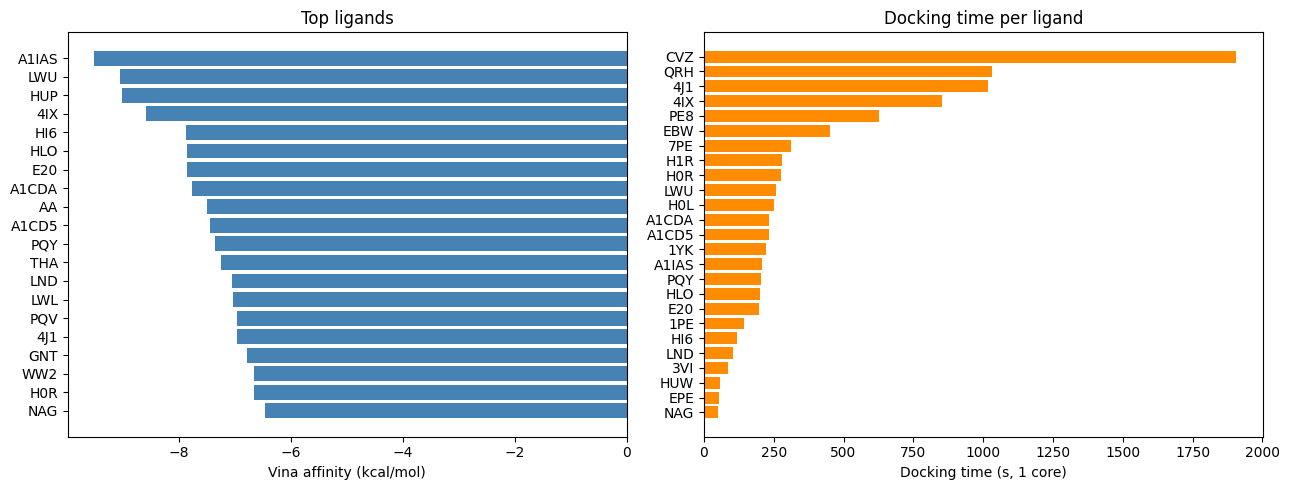

In [ ]:
res = pd.DataFrame(results)
suffix = f"_part{part}of{n_parts}" if n_parts > 1 else ""
part_ligands = ligands if n_parts == 1 else ligands[ligands["accession"].isin(res["accession"])]
table = (part_ligands.merge(res, on="accession", how="left")
         .assign(torsions=lambda d: d["accession"].map(torsions))
         .sort_values("best_affinity"))
cols = ["accession", "name", "additive", "num_atoms", "torsions", "hotspot_residues", "best_affinity",
        "pose_hotspot_residues", "dock_time_s", "status"]
table = table[cols].round(2)
table.to_csv(os.path.join(root, f"docking_results{suffix}.csv"), index=False)
display(table)

ok = table.dropna(subset=["best_affinity"]).head(20)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh(ok["accession"], ok["best_affinity"], color="steelblue"); ax[0].invert_yaxis()
ax[0].set_xlabel("Vina affinity (kcal/mol)"); ax[0].set_title("Top ligands")
t_ok = table[table["dock_time_s"] > 0].sort_values("dock_time_s", ascending=False).head(25)
ax[1].barh(t_ok["accession"], t_ok["dock_time_s"], color="darkorange"); ax[1].invert_yaxis()
ax[1].set_xlabel("Docking time (s, 1 core)"); ax[1].set_title("Docking time per ligand")
plt.tight_layout(); plt.savefig(os.path.join(root, f"docking_summary{suffix}.png"), dpi=300); plt.show()

## 10. Best complex

In [ ]:
from biobb_vs.utils.extract_model_pdbqt import extract_model_pdbqt
from biobb_structure_utils.utils.cat_pdb import cat_pdb

best = res.dropna(subset=["best_affinity"]).sort_values("best_affinity").iloc[0]
print(f"Best: {best['accession']} at {best['best_affinity']} kcal/mol (touches {best['pose_hotspot_residues']} hotspot residues)")
pose_pdbqt, pose_pdb, complex_pdb = (os.path.join(root, n) for n in ("best_pose.pdbqt", "best_pose.pdb", "best_complex.pdb"))
extract_model_pdbqt(input_pdbqt_path=best["pose_file"], output_pdbqt_path=pose_pdbqt, properties={"model": 1})
babel_convert(input_path=pose_pdbqt, output_path=pose_pdb,
              properties={"input_format": "pdbqt", "output_format": "pdb", "binary_path": "obabel"})
cat_pdb(input_structure1=af_pdb, input_structure2=pose_pdb, output_structure_path=complex_pdb)
print("Complex written:", complex_pdb)

Best: A1IAS at -9.51 kcal/mol (touches 13 hotspot residues)
2026-10-18 17:10:42,913 [MainThread  ] [INFO ]  Module: biobb_vs.utils.extract_model_pdbqt Version: 5.3.0


INFO:log_171.out:Module: biobb_vs.utils.extract_model_pdbqt Version: 5.3.0


2026-10-18 17:10:42,915 [MainThread  ] [INFO ]  Directory successfully created: /content/sandbox_d49a2a28-67c7-4442-8a8c-00748145a9ec


INFO:log_171.out:Directory successfully created: /content/sandbox_d49a2a28-67c7-4442-8a8c-00748145a9ec


2026-10-18 17:10:42,918 [MainThread  ] [INFO ]  Copy to stage: docking_P22303/docking/A1IAS_out.pdbqt --> sandbox_d49a2a28-67c7-4442-8a8c-00748145a9ec


INFO:log_171.out:Copy to stage: docking_P22303/docking/A1IAS_out.pdbqt --> sandbox_d49a2a28-67c7-4442-8a8c-00748145a9ec


... (31 outputs left out)

INFO:log_173.out:Removed: ['/content/sandbox_2f006667-4727-4826-9914-72f4c991ebeb']


2026-10-18 17:10:43,071 [MainThread  ] [INFO ]  


INFO:log_173.out:


Complex written: docking_P22303/best_complex.pdb


In [ ]:
import nglview
view = nglview.NGLWidget()
p = view.add_component(nglview.FileStructure(af_pdb)); p.clear()
p.add_representation("cartoon", colorScheme="bfactor")
p.add_representation("surface", selection=", ".join(map(str, box_res)), color="pink", opacity=0.4, lowResolution=True)
l = view.add_component(nglview.FileStructure(pose_pdb)); l.clear()
l.add_representation("licorice", color="green", radius=0.5)
view.center(); view._remote_call("setSize", target="Widget", args=["", "550px"])
view

NGLWidget()

## 11. Runtime summary

In [ ]:
total = time.perf_counter() - T_START
print("Step timings (s):")
for k, v in TIMINGS.items(): print(f"  {k:<18} {v:8.1f}")
n_ok = int(table["status"].fillna("").str.startswith("ok").sum())
print(f"\nLigands docked: {n_ok} | workers: {n_workers} | profile: {PROFILE}")
print(f"Mean docking time per ligand (1 core): {table.loc[table['dock_time_s'] > 0, 'dock_time_s'].mean():.1f} s")
print(f"TOTAL wall-clock since the parameter cell: {total:.1f} s ({total/60:.1f} min) - excludes the one-off install")

Step timings (s):
  alphafold               0.5
  pdbe_kb                 1.5
  receptor_and_box        6.2
  ligand_prep            10.8
  docking_wall         5188.7

Ligands docked: 58 | workers: 2 | profile: standard
Mean docking time per ligand (1 core): 173.1 s
TOTAL wall-clock since the parameter cell: 5259.6 s (87.7 min) - excludes the one-off install
